**Burgers_Equation**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 2.0 * np.pi
U = 1.0
nu = 0.1
a = 0.95
nx = 256
plot_times = [0.0, 1.0, 3.0, 6.0]
safety = 0.8

k = 2.0 * np.pi / L
dx = L / nx
x = np.linspace(0.0, L, nx, endpoint=False)

**Evaluate the exact solution**

accepts an array of positions, so NumPy evaluates the entire profile at once

In [2]:
def exact_solution(x, t, nu, U, a, L):
    '''Evaluate the smooth periodic Burgers solution.'''
    k = 2.0 * np.pi / L
    q = a * np.exp(-nu * k**2 * t)
    theta = k * (x - U * t)
    return U + 2.0 * nu * k * q * np.sin(theta) / (
        1.0 + q * np.cos(theta)
    )


Check that $0<a<1$ and that viscosity is positive, evaluated at $t=0$

In [3]:
assert 0.0 < a < 1.0
assert nu > 0.0

u0 = exact_solution(x, 0.0, nu, U, a, L)
print(f'Initial velocity range: {u0.min():.3f} to {u0.max():.3f}')
print(f'One circuit at mean speed U takes L/U = {L/U:.3f}')

Initial velocity range: 0.392 to 1.608
One circuit at mean speed U takes L/U = 6.283


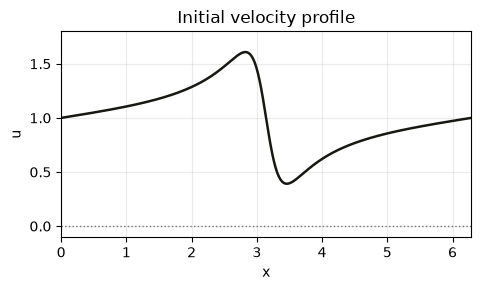

In [4]:
fig_initial, ax_initial = plt.subplots(figsize=(5.0, 3.0))
ax_initial.plot(
    np.append(x, L), np.append(u0, u0[0]),
    color='#181712', linewidth=1.8,
)
ax_initial.axhline(0.0, color='#787876', linestyle=':', linewidth=1)
ax_initial.set(xlabel='x', ylabel='u', title='Initial velocity profile',
               xlim=(0.0, L), ylim=(-0.1, 1.8))
ax_initial.grid(alpha=0.25)
fig_initial.tight_layout()
plt.show()

In [5]:
assert np.all(u0 > 0.0)

All values from u_0 is positive


**The pointwise update**

multiplies the local velocity right at grid point $i$ ($u_i$) by the local slope or change happening right there ($u_i - u_{i-1}$).

In [6]:
def burgers_step(u, dt, dx, nu):
    '''Take one periodic pointwise-convection/centered-diffusion step.'''
    left = np.roll(u, 1)
    right = np.roll(u, -1)
    return (
        u - dt / dx * u * (u - left)
        + nu * dt / dx**2 * (right - 2.0 * u + left)
    )


**The conservative update**

whatever leaves cell $i-1$ is guaranteed to enter cell $i$, the fluxes telescope cleanly across the whole domain. This preserves the total quantity of the wave and automatically obeys physical laws (like the Rankine-Hugoniot jump conditions) to place shocks at the correct speed.

In [7]:
def conservative_burgers_step(u, dt, dx, nu):
    '''Take one periodic conservative-convection/centered-diffusion step.'''
    left = np.roll(u, 1)
    right = np.roll(u, -1)
    return (
        u - dt / dx * (0.5 * u**2 - 0.5 * left**2)
        + nu * dt / dx**2 * (right - 2.0 * u + left)
    )

On-paper #3

In [8]:
# Hand-checkable periodic update: left neighbors are [1, 1, 2].
u_test = np.array([1.0, 2.0, 1.0])
np.testing.assert_allclose(
    burgers_step(u_test, dt=0.1, dx=1.0, nu=0.1),
    [1.01, 1.78, 1.11],
)
np.testing.assert_allclose(
    conservative_burgers_step(u_test, dt=0.1, dx=1.0, nu=0.1),
    [1.01, 1.83, 1.16],
)
np.testing.assert_array_equal(u_test, [1.0, 2.0, 1.0])
for step in (burgers_step, conservative_burgers_step):
    constant = np.full(5, 1.5)
    np.testing.assert_allclose(step(constant, 0.1, 1.0, 0.1), constant)
print('One-step values, unchanged input, and constant-state checks pass.')

One-step values, unchanged input, and constant-state checks pass.


**Find the fastest part of the wave, gear down by 20% for safety, and use that same pacing all the way through.**

**Adjust our step size slightly so we never overshoot our target checkpoints.**

**Keep two separate clipboards so the two methods don't accidentally contaminate each other's data.**

**Use assertions to constantly inspect the math to make sure nothing explodes, nothing escapes its boundaries, and the conservative method's mass-conservation is practically flawless.**

In [10]:
# Both methods start independently and use exactly the same time steps.
assert 0.0 < safety <= 1.0
dt_target = safety / (u0.max() / dx + 2.0 * nu / dx**2)
methods = {
    'Pointwise': burgers_step,
    'Conservative': conservative_burgers_step,
}
states = {name: u0.copy() for name in methods}
snapshots = {name: [u0.copy()] for name in methods}
step_counts = [0]
time = 0.0
total_steps = 0
max_mean_drift = {name: 0.0 for name in methods}

for target_time in plot_times[1:]:
    num_steps = int(np.ceil((target_time - time) / dt_target))
    dt = (target_time - time) / num_steps
    for _ in range(num_steps):
        for name, step in methods.items():
            states[name] = step(states[name], dt, dx, nu)
            actual = states[name]
            assert np.all(np.isfinite(actual))
            assert actual.min() >= u0.min() - 1e-12
            assert actual.max() <= u0.max() + 1e-12
            max_mean_drift[name] = max(
                max_mean_drift[name], abs(actual.mean() - u0.mean())
            )
    total_steps += num_steps
    for name in methods:
        snapshots[name].append(states[name].copy())
    step_counts.append(total_steps)
    time = target_time

assert max_mean_drift['Conservative'] < 1e-12
print(f'Target time step: {dt_target:.6f}')
print(f'Total steps per method to t={time:g}: {total_steps}')
print('Maximum absolute mean drift over all steps:', max_mean_drift)

Target time step: 0.002012
Total steps per method to t=6: 2982
Maximum absolute mean drift over all steps: {'Pointwise': np.float64(0.004527293849151182), 'Conservative': np.float64(3.3306690738754696e-16)}


**Compare the profiles**

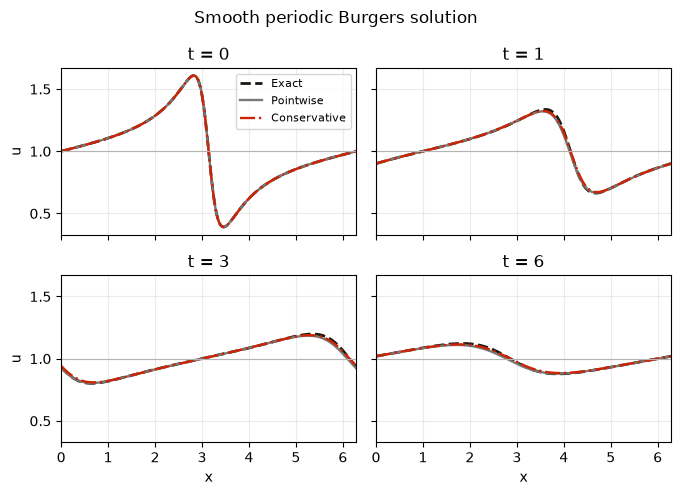

In [11]:
x_plot = np.append(x, L)
fig, axes = plt.subplots(2, 2, figsize=(7.0, 5.0), sharex=True, sharey=True)
styles = {'Pointwise': ('#787876', '-'), 'Conservative': ('#ce2406', '-.')}

for j, (ax, t) in enumerate(zip(axes.flat, plot_times)):
    reference = exact_solution(x, t, nu, U, a, L)
    ax.plot(x_plot, np.append(reference, reference[0]),
            color='#181712', linestyle='--', linewidth=2, label='Exact')
    for name, (color, linestyle) in styles.items():
        numerical = snapshots[name][j]
        ax.plot(x_plot, np.append(numerical, numerical[0]),
                color=color, linestyle=linestyle, linewidth=1.7, label=name)
    ax.axhline(U, color='#b4b4b2', linewidth=0.8)
    ax.set_title(f't = {t:g}')
    ax.set_xlim(0.0, L)
    ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)
for ax in axes[-1, :]:
    ax.set_xlabel('x')
for ax in axes[:, 0]:
    ax.set_ylabel('u')
fig.suptitle('Smooth periodic Burgers solution', fontsize=12)
fig.tight_layout()
plt.show()

Look at the key and see that the pointwise strays away from the consverative slightly

In [12]:
print(f"{'Time':>5} {'Method':>13} {'Steps':>7} "
      f"{'Maximum error':>16} {'Mean drift':>16}")
for j, (t, steps) in enumerate(zip(plot_times, step_counts)):
    reference = exact_solution(x, t, nu, U, a, L)
    for name in methods:
        numerical = snapshots[name][j]
        error = np.max(np.abs(numerical - reference))
        drift = numerical.mean() - u0.mean()
        print(f'{t:5.1f} {name:>13} {steps:7d} '
              f'{error:16.6e} {drift:16.6e}')

 Time        Method   Steps    Maximum error       Mean drift
  0.0     Pointwise       0     0.000000e+00     0.000000e+00
  0.0  Conservative       0     0.000000e+00     0.000000e+00
  1.0     Pointwise     497     3.535923e-02    -2.836582e-03
  1.0  Conservative     497     2.116956e-02     1.110223e-16
  3.0     Pointwise    1491     2.842043e-02    -4.024369e-03
  3.0  Conservative    1491     1.438802e-02    -1.110223e-16
  6.0     Pointwise    2982     2.160500e-02    -4.527294e-03
  6.0  Conservative    2982     1.014646e-02     1.110223e-16


**Instead of rewriting code for every single experiment, this function acts as a reusable wrapper that loops through your time steps using conservative_burgers_step(). It doesn't change any of the underlying math; it just manages the logistics.**

In [ ]:

def advance_periodic_burgers(initial_state, dx, nu, times, safety=0.8):
    '''Advance positive periodic data and save the requested profiles.'''
    assert np.all(initial_state > 0.0)
    assert nu > 0.0
    assert 0.0 < safety <= 1.0
    assert times[0] == 0.0 and np.all(np.diff(times) > 0.0)

    lower = initial_state.min()
    upper = initial_state.max()
    dt_target = safety / (upper / dx + 2.0 * nu / dx**2)
    state = initial_state.copy()
    profiles = [state.copy()]

    for start, end in zip(times[:-1], times[1:]):
        num_steps = int(np.ceil((end - start) / dt_target))
        dt = (end - start) / num_steps
        for _ in range(num_steps):
            state = conservative_burgers_step(state, dt, dx, nu)
        assert np.all(np.isfinite(state))
        assert state.min() >= lower - 1e-12
        assert state.max() <= upper + 1e-12
        assert abs(state.mean() - initial_state.mean()) < 1e-12
        profiles.append(state.copy())

    return profiles
    

**Hold the initial data fixed**

In [14]:
sine_amplitude = 0.75
sine_nx = 512
sine_dx = L / sine_nx
sine_x = np.linspace(0.0, L, sine_nx, endpoint=False)
sine_initial = U + sine_amplitude * np.sin(2.0 * np.pi * sine_x / L)
sine_times = [0.0, 0.5, 1.0, 2.0]
viscosities = [0.5, 0.05]

sine_profiles = {}
for viscosity in viscosities:
    sine_profiles[viscosity] = advance_periodic_burgers(
        sine_initial, sine_dx, viscosity, sine_times, safety,
    )

The panels use common axes. **Gray shows the larger viscosity**; **red shows the smaller one**. At zero time the curves coincide because their **initial conditions are identical**. A duplicated endpoint closes each curve for plotting only.

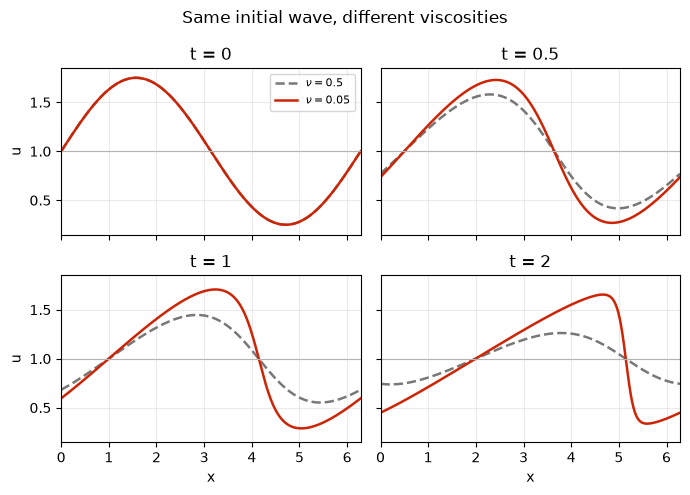

In [15]:
sine_x_plot = np.append(sine_x, L)
fig_sine, axes_sine = plt.subplots(
    2, 2, figsize=(7.0, 5.0), sharex=True, sharey=True,
)
viscosity_styles = {
    0.5: ('#787876', '--'),
    0.05: ('#ce2406', '-'),
}
for j, (ax, time) in enumerate(zip(axes_sine.flat, sine_times)):
    for viscosity in viscosities:
        profile = sine_profiles[viscosity][j]
        color, linestyle = viscosity_styles[viscosity]
        ax.plot(
            sine_x_plot, np.append(profile, profile[0]),
            color=color, linestyle=linestyle, linewidth=1.8,
            label=fr'$\nu={viscosity:g}$',
        )
    ax.axhline(U, color='#b4b4b2', linewidth=0.8)
    ax.set_title(f't = {time:g}')
    ax.set_xlim(0.0, L)
    ax.set_ylim(0.15, 1.85)
    ax.grid(alpha=0.25)
axes_sine[0, 0].legend(fontsize=8)
for ax in axes_sine[-1, :]:
    ax.set_xlabel('x')
for ax in axes_sine[:, 0]:
    ax.set_ylabel('u')
fig_sine.suptitle('Same initial wave, different viscosities', fontsize=12)
fig_sine.tight_layout()
plt.show()

To answer the question: **Is your grid fine enough** that the thickness of the front is strictly controlled by your true physical viscosity ($\nu$)?
Or **is your grid too coarse**, meaning the computer's math and grid spacing are artificially smearing out the wave and dictating its thickness regardless of what your viscosity parameter is set to?

-We can compare 256, 512, and 1024 points, recomputing the permitted time step on each grid. Reuse the existing 512-point run.



In [16]:
front_viscosity = 0.05
front_grids = [256, 512, 1024]
front_results = {
    sine_nx: (sine_x, sine_dx, sine_profiles[front_viscosity][-1]),
}
for grid_size in front_grids:
    if grid_size == sine_nx:
        continue
    grid_dx = L / grid_size
    grid_x = np.linspace(0.0, L, grid_size, endpoint=False)
    initial = U + sine_amplitude * np.sin(2.0 * np.pi * grid_x / L)
    profiles = advance_periodic_burgers(
        initial, grid_dx, front_viscosity, sine_times, safety,
    )
    front_results[grid_size] = (grid_x, grid_dx, profiles[-1])

print(f"{'Points':>8} {'Steepest descending slope':>27} "
      f"{'Difference to next grid':>25}")
for j, grid_size in enumerate(front_grids):
    grid_x, grid_dx, final = front_results[grid_size]
    derivative = (np.roll(final, -1) - np.roll(final, 1)) / (2.0 * grid_dx)
    if j < len(front_grids) - 1:
        finer = front_results[front_grids[j + 1]][2]
        difference = np.max(np.abs(final - finer[::2]))
        difference_text = f'{difference:.6f}'
    else:
        difference_text = '—'
    print(f'{grid_size:8d} {derivative.min():27.3f} '
          f'{difference_text:>25}')

  Points   Steepest descending slope   Difference to next grid
     256                      -3.487                  0.032574
     512                      -3.837                  0.019059
    1024                      -4.056                         —


As we can see in our result, the slope is increasing as we refine our grid thus this is not a completely viscosity driven system. The negatives mean we are descending. **To get a viscosity-driven system we must refine down to a point where our slope stops changing between mesh sizes.**

### Agent Work

You will supply the numerical question, predict the behavior, inspect the agent’s proposed experiment, and decide what the evidence supports. The agent will draft code to organize the runs and measurements without changing the numerical method.

## Agent Task Brief

**Goal and Interface:**

Execute a space–time convergence study for the 1D viscous Burgers' equation using the conservative finite-difference scheme.

**Required Functions & Argument Orders** 

**exact_solution(x, t, L, U, nu, a):** Evaluates the analytical reference solution.
Arguments: Spatial coordinates (x), time (T), domain length (L), baseline velocity (U), kinematic viscosity (nu), and amplitude parameter (a).

**conservative_burgers_step(u, L, nu, dt, dx):** Evaluates a single time-step update using conservative fluxes and centered diffusion.
Arguments: Current velocity array (u), domain length (L), kinematic viscosity (nu), time step (dt), and spatial spacing (dx).

**advance_periodic_burgers(u0, L, nu, T, safety, nx):** Advances the initial profile over time using the conservative step runner.
Arguments: Initial velocity array (u0), domain length (L), kinematic viscosity (nu), final time (T), CFL safety factor (safety), and grid resolution (nx). Function argument nx corresponds to $N$

Internal Execution: Must repeatedly invoke conservative_burgers_step() while enforcing the combined convective-diffusive time-step bound scaled by safety.


**Fixed Problem Data**
Domain & Physics: $L = 2\pi$, $U = 1.0$, $\nu = 0.1$, $a = 0.95$.
Grid Sizes ($N$): $128, 256, 512, 1024$    (unique periodic grids using distinct experiment variable names).
Time Parameters: Final simulation time $T = 1.0$ (run continuously from $t = 0$ to $T$; metrics $E_N, R_N, p_N$ are evaluated strictly at the final time $T = 1.0$).
Stability Control: CFL safety factor = $0.8$ in the combined step restriction.
Initial Data: Must use the reference initial profile generated by exact_solution() at $t = 0$ (do not use the sine initial condition from the viscosity study).

**Required Retained Artifacts & Table**
Retained Arrays per Grid:
Spatial positions ($x$)
Initial array ($u_0$)
Computed final array ($u_{\text{computed}}$) at $T = 1.0$
Exact final array ($u_{\text{exact}}$) evaluated via exact_solution() at $T = 1.0$
Measured pointwise error array ($e = \vert{}u_{\text{computed}} - u_{\text{exact}}\vert{}\,${}{})
Required Summary Table: Must output a single table containing the following columns:
Grid size ($N$)
Spatial spacing ($\Delta x$)
Time-step count ($N_t$)
Actual time step ($\Delta t$)
Maximum error ($E_N = \max_i \vert{}u_{i,\text{computed}} - u(x_i, T)\vert{}${} {})
Error ratio ($R_N = \frac{E_N}{E_{2N}}$)
Observed order ($p_N = \frac{\log(R_N)}{\log 2}$)
Formatting Rule for Table: Place each ratio ($R_N$) and order ($p_N$) on the coarser row of its grid pair; leave them blank on the final row ($N = 1024$).



**Scope:**

Add unexecuted experiment cells at the end of your notebook adhering strictly to the operational scope below:

**Operational Constraints & Rules**
No Function Redefinition: Do not redefine, modify, or overwrite the three existing core functions (exact_solution, conservative_burgers_step, and advance_periodic_burgers).

Environment Restrictions: Do not modify earlier cells, install external packages, access the network, or execute code blocks.

No Visuals or Interpretations: Do not generate plots, figures, or qualitative analytical interpretations.

**Required Experiment Cell Logic**
Parameter Initialization: Set fixed problem variables using distinct experiment variable names:
$$L = 2\pi$$
$$U = 1.0$$
$$\nu = 0.1$$
$$a = 0.95$$
$$T = 1.0$$
$$\text{safety} = 0.8$$
Grid array: $N \in \{128, 256, 512, 1024\}$   
Grid & Initial Data Generation:
For each $N$, define spatial grid positions $x_i = i \Delta x$ where $\Delta x = L / N$ for $i = 0, 1, \dots, N-1$.
Obtain the initial profile using exact_solution(x, t=0.0, L, U, nu, a).

Time-Step & Count Derivation:
Compute the maximum velocity magnitude $M = \max_i \vert{}u_i^0\vert{}${}{} from the initial array.
Calculate the combined stable time step using the step restriction formula: $\Delta t_{\text{max}} = \left(\frac{M}{\Delta x} + \frac{2\nu}{\Delta x^2}\right)^{-1}$.
Apply the safety factor: $\Delta t_{\text{trial}} = \text{safety} \cdot \Delta t_{\text{max}}$.
Determine total step count $N_t = \lceil T / \Delta t_{\text{trial}} \rceil$ and adjust the actual time step to land exactly on $T$: $\Delta t = T / N_t$.

Execution & Data Retention:
Call advance_periodic_burgers() using the distinct experiment variables and the derived parameters.
Retain per-grid arrays: spatial positions ($x$), initial array ($u_0$), computed final array ($u_{\text{computed}}$), exact reference final array evaluated via exact_solution(x, T, L, U, nu, a), and absolute pointwise error array ($e = \vert{}u_{\text{computed}} - u_{\text{exact}}\vert{}${}{}).

Metrics & Summary Table Generation:
Compute maximum error $E_N = \max_i e_i$ for each grid.
Compute error ratios $R_N = E_N / E_{2N}$ and observed orders $p_N = \log(R_N) / \log 2$ for grid pairs ($128/256$, $256/512$, $512/1024$).
Assemble and output the final table containing columns for Grid Size ($N$), Spacing ($\Delta x$), Step Count ($N_t$), Actual $\Delta t$, Max Error ($E_N$), Error Ratio ($R_N$), and Observed Order ($p_N$). Ensure ratios and orders are placed on the coarser row of each pair and left blank on the final row ($N = 1024$).

**Acceptance Evidence:**

To validate the execution and ensure rigorous quantitative integrity, the experiment cells must satisfy the following acceptance evidence criteria:

Fresh Initial Data Generation: Every grid resolution ($N \in \{128, 256, 512, 1024\}$) must independently initialize its spatial coordinates and generate its starting profile using exact_solution(x, t=0.0, L, U, nu, a) rather than reusing or modifying arrays from prior runs or separate experiments.

Exact Final Time Target: Every simulation must march forward dynamically using its computed step count and adjusted time step to land precisely at the uniform final time $T = 1.0$.

Dynamic Measurement Computation: All metrics ($E_N$, $R_N$, and $p_N$) must be computed programmatically directly from the retained arrays ($x$, $u_0$, $u_{\text{computed}}$, $u_{\text{exact}}$, and pointwise error $e = \vert{}u_{\text{computed}} - u_{\text{exact}}\vert{}${}{}).

Prohibition of Hard-Coding: Do not hard-code maximum errors, error ratios, or observed orders.

No Parameter Tuning: Do not adjust numerical schemes, time-step bounds, or problem parameters to force or manipulate the solution into matching theoretical convergence trends.

## What the Agent Returned

### Space–time convergence experiment — unexecuted, ready for audit

Independently generate exact initial data on unique periodic grids with N = 128, 256, 512, 1024, using L = 2π, U = 1.0, ν = 0.1, a = 0.95. Advance the existing conservative scheme continuously from 0 to T = 1.0 with safety = 0.8. Retain each grid's initial, computed final, exact final, and absolute error arrays; report maximum errors, paired ratios, and observed orders in one table.

**Interface audit:** No numerical inputs are missing. The brief's argument orders differ from the existing definitions. These additions use the existing keyword interfaces without redefining any function:
- `exact_solution(x, t, nu, U, a, L)`
- `conservative_burgers_step(u, dt, dx, nu)` (called internally by the existing runner)
- `advance_periodic_burgers(initial_state, dx, nu, times, safety=0.8)`

The runner returns initial and final profiles for `times=[0.0, T]`. It computes its own constant step count and adjusted time step; the experiment derives the same values for reporting. Positivity is checked so the runner's initial maximum equals the required maximum magnitude. The runner already checks finite values, bounds, and conservation. This is a joint space–time refinement study with the prescribed stability bound.

**Execution prerequisites:** NumPy and the three existing function definitions must be available when you choose to run these cells. No cells were executed during drafting; no measured results or interpretations are supplied.

In [20]:
# Fixed experiment parameters; leave earlier experiment names untouched.
conv_L = 2.0 * np.pi
conv_U = 1.0
conv_nu = 0.1
conv_a = 0.95
conv_T = 1.0
conv_safety = 0.8
conv_grid_sizes = (128, 256, 512, 1024)
conv_times = [0.0, conv_T]
conv_results = {}

In [21]:
# Each run starts from fresh exact data on its own unique periodic grid.
for conv_N in conv_grid_sizes:
    conv_dx = conv_L / conv_N
    conv_x = np.arange(conv_N, dtype=float) * conv_dx
    conv_u0 = exact_solution(
        x=conv_x, t=0.0, L=conv_L, U=conv_U, nu=conv_nu, a=conv_a,
    )
    assert np.all(np.isfinite(conv_u0)) and np.all(conv_u0 > 0.0)
    conv_M = float(np.max(np.abs(conv_u0)))
    conv_dt_max = 1.0 / (conv_M / conv_dx + 2.0 * conv_nu / conv_dx**2)
    # Same operation order as the existing runner, avoiding ceil roundoff differences.
    conv_dt_trial = conv_safety / (
        conv_M / conv_dx + 2.0 * conv_nu / conv_dx**2
    )
    conv_Nt = int(np.ceil(conv_T / conv_dt_trial))
    conv_dt = conv_T / conv_Nt
    assert conv_dt <= conv_dt_trial
    assert np.isclose(conv_Nt * conv_dt, conv_T, rtol=0.0, atol=1e-14)

    # The runner recomputes this same Nt and dt for the single interval [0, T].
    conv_profiles = advance_periodic_burgers(
        initial_state=conv_u0.copy(), dx=conv_dx, nu=conv_nu,
        times=conv_times, safety=conv_safety,
    )
    conv_computed = conv_profiles[-1].copy()
    conv_exact = exact_solution(
        x=conv_x, t=conv_T, L=conv_L, U=conv_U, nu=conv_nu, a=conv_a,
    )
    conv_error = np.abs(conv_computed - conv_exact)
    conv_results[conv_N] = {
        "x": conv_x.copy(),
        "u_0": conv_u0.copy(),
        "u_computed": conv_computed,
        "u_exact": conv_exact.copy(),
        "e": conv_error.copy(),
        "dx": conv_dx,
        "N_t": conv_Nt,
        "dt": conv_dt,
        "dt_max": conv_dt_max,
        "dt_trial": conv_dt_trial,
        "T": conv_T,
        "E_N": float(np.max(conv_error)),
    }

In [33]:
# Compute paired metrics from retained errors; place them on the coarser row.
for conv_N in conv_grid_sizes:
    conv_record = conv_results[conv_N]
    conv_record["E_N"] = float(np.max(conv_record["e"]))
    conv_record["R_N"] = None
    conv_record["p_N"] = None

for conv_coarse, conv_fine in zip(conv_grid_sizes[:-1], conv_grid_sizes[1:]):
    assert conv_fine == 2 * conv_coarse
    conv_E_coarse = conv_results[conv_coarse]["E_N"]
    conv_E_fine = conv_results[conv_fine]["E_N"]
    assert conv_E_coarse > 0.0 and conv_E_fine > 0.0, (
        "Ratios and log orders require positive measured errors."
    )
    conv_ratio = conv_E_coarse / conv_E_fine
    conv_results[conv_coarse]["R_N"] = conv_ratio
    conv_results[conv_coarse]["p_N"] = float(np.log(conv_ratio) / np.log(2.0))

# One summary table; the finest row has blank ratio and order fields.
print(f"{'N':>6} {'dx':>14} {'N_t':>9} {'dt':>14} "
      f"{'E_N':>14} {'R_N':>12} {'p_N':>12}")
for conv_N in conv_grid_sizes:
    conv_record = conv_results[conv_N]
    conv_ratio_text = (
        "" if conv_record["R_N"] is None else f'{conv_record["R_N"]:.6f}'
    )
    conv_order_text = (
        "" if conv_record["p_N"] is None else f'{conv_record["p_N"]:.6f}'
    )
    print(f'{conv_N:6d} {conv_record["dx"]:14.7e} '
          f'{conv_record["N_t"]:9d} {conv_record["dt"]:14.7e} '
          f'{conv_record["E_N"]:14.7e} '
          f'{conv_ratio_text:>12} {conv_order_text:>12}')

     N             dx       N_t             dt            E_N          R_N          p_N
   128  4.9087385e-02       145  6.8965517e-03  3.7143215e-02     1.754558     0.811108
   256  2.4543693e-02       497  2.0120724e-03  2.1169557e-02     1.848440     0.886308
   512  1.2271846e-02      1824  5.4824561e-04  1.1452663e-02     1.915453     0.937686
  1024  6.1359232e-03      6968  1.4351320e-04  5.9790876e-03                          


## Independent Calculation for N = 256

In [35]:
import numpy as np

# Select grid pair to audit (N = 256 as coarse, N = 512 as fine)
n_coarse = conv_grid_sizes[1]  # 256
n_fine = conv_grid_sizes[2]    # 512

# 1. Pull saved spatial positions and computed solutions from conv_results
x_coarse = conv_results[n_coarse]["x"]
u_comp_coarse = conv_results[n_coarse]["u_computed"]

x_fine = conv_results[n_fine]["x"]
u_comp_fine = conv_results[n_fine]["u_computed"]

# 2. Make fresh, independent calls to exact_solution() at T = conv_T
u_exact_coarse = exact_solution(
    x=x_coarse, t=conv_T, L=conv_L, U=conv_U, nu=conv_nu, a=conv_a
)
u_exact_fine = exact_solution(
    x=x_fine, t=conv_T, L=conv_L, U=conv_U, nu=conv_nu, a=conv_a
)

# 3. Recompute maximum errors independently (bypassing stored error fields)
E_coarse_fresh = np.max(np.abs(u_comp_coarse - u_exact_coarse))
E_fine_fresh = np.max(np.abs(u_comp_fine - u_exact_fine))

# 4. Calculate independent error ratio and observed order
audit_ratio = E_coarse_fresh / E_fine_fresh
audit_order = np.log2(audit_ratio)

# 5. Print comparison against the agent's table values
print(f"=== INDEPENDENT AUDIT (N = {n_coarse} & {n_fine}) ===")
print(f"Freshly Recomputed E_{n_coarse}: {E_coarse_fresh:.7e}")
print(f"Freshly Recomputed E_{n_fine}:   {E_fine_fresh:.7e}")
print(f"Calculated Error Ratio (R_N):   {audit_ratio:.6f}   (Table: {conv_results[n_coarse]['R_N']:.6f})")
print(f"Calculated Observed Order (p_N):{audit_order:.6f}   (Table: {conv_results[n_coarse]['p_N']:.6f})")
print("==================================================")


=== INDEPENDENT AUDIT (N = 256 & 512) ===
Freshly Recomputed E_256: 2.1169557e-02
Freshly Recomputed E_512:   1.1452663e-02
Calculated Error Ratio (R_N):   1.848440   (Table: 1.848440)
Calculated Observed Order (p_N):0.886308   (Table: 0.886308)


**Confirmed the Same**